In [1]:
import os
import utils
import visualisation
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from matplotlib import colormaps
from pathlib import Path

from pymer4.models import lmer, lm, glm, glmer
from fit_psyche.psychometric_curve import PsychometricCurve
from matplotlib.lines import Line2D

In [2]:
def get_estimates(data):
    steps = data.coherence_level.unique()
    cond_labels = data.counterfactual_label.unique()
    
    output = {}

    for ix, cond in enumerate(cond_labels):
        cond_data = data.loc[
            data.counterfactual_label == cond
        ]
        coherence, prob_correct = np.split(cond_data.groupby("coherence_level").response_correct.mean().reset_index().to_numpy(), 2, 1)
        coherence = coherence.flatten()
        prob_correct = prob_correct.flatten()

        wh = PsychometricCurve(model='wh', guess_rate_lims=[0.000000, 0.000001]).fit(coherence, prob_correct)

        coherence_median = np.median(cond_data.loc[cond_data.response_correct==True].coherence_level.to_numpy())

        coherence_sigmoid_mean = steps[np.argmin(np.abs(steps - wh.coefs_["mean"]))]
        
        coherence_outer = np.percentile(cond_data.loc[cond_data.response_correct==True].coherence_level.to_numpy(), 90)

        coherence_split_distance = coherence_median - (coherence_median - coherence_sigmoid_mean)/2

        coherence_split = steps[np.argmin(np.abs(steps - coherence_split_distance))]

        all_good = coherence_sigmoid_mean < coherence_split < coherence_median < coherence_outer

        if not all_good:
            coherence_split = steps[np.argmax(steps < coherence_sigmoid_mean)]
        
        output[cond] = [coherence_sigmoid_mean, coherence_split, coherence_median, coherence_outer]

    return output



def print_train_results(all_blocks, print=None):
    estimates = get_estimates(all_blocks.iloc[70:])
    curves = {}
    box_style = {
        'whiskerprops': {'linewidth': 0.5, 'color': 'gray'},
        'medianprops': {'linewidth': 0.5, 'color': 'gray'},
        'boxprops': {'color': 'gray', 'linewidth': 0.5},
        'capprops': {'color': 'gray', 'linewidth': 0.5}
    }

    colours = ["#9b5de5", "#f15bb5"]
    x = np.linspace(-0.2, 1.2, num=500)
    f, ax = plt.subplots(1,2, figsize=(10, 5))
    for ix, cond in enumerate(all_blocks.counterfactual_label.unique()):
        
        ax[ix].set_ylim(-0.1, 1.1)
        ax[ix].set_ylabel("Proportion of correct responses")
        ax[ix].yaxis.label.set_color(colours[ix])
        ax[ix].set_xlim(0.0, 0.5)
        ax[ix].set_xlabel("Proportion of target dots")
        ax[ix].set_xticks(np.linspace(0.0, 0.5, num=6))
        coh = []
        prob = []
        cond_data = all_blocks.loc[
            (all_blocks.counterfactual_label == cond)
        ]
        coherence, prob_correct = np.split(cond_data.groupby("coherence_level").response_correct.mean().reset_index().to_numpy(), 2, 1)
        coherence = coherence.flatten()
        prob_correct = prob_correct.flatten()
        ax[ix].scatter(coherence, prob_correct, s=50, color=colours[ix], label="Data", lw=1, edgecolors="black")
        wh = PsychometricCurve(model='wh', guess_rate_lims=[0.0, 0.000001]).fit(coherence, prob_correct)
        curve = wh.predict(x)
        ax[ix].plot(x, curve, label=f"Curve fit", c=colours[ix], lw=5, alpha=0.5)
        curves[cond] = [x, curve]

        ax[ix].set_title(f"Counterfactual evidence level: {cond}")

        ax[ix].set_xlim(coherence[0] - 0.05, coherence[-1] + 0.02)
        labs = ["50%", "60%", "70%"]
        for ord, est in enumerate(estimates[cond][:3]):
            est_ix = np.where(x >= est)[0][0]
            bottom = curve[est_ix]
            ax[ix].plot([est, est], [bottom, 1.1], lw=5, c="black", alpha=0.3)
            ax[ix].text(
                est, 1, f"{labs[ord]}",
                horizontalalignment="center",
                verticalalignment="center",
                size="small",
                weight="bold",
                family="sans-serif",
                alpha=0.5
            )

        ax2 = ax[ix].twinx()
        ax2.set_ylim(-10, 110)
        ax2.set_ylabel("Confidence [%]")

        coh, mean_conf = np.split(cond_data.loc[cond_data.response_correct==True].groupby(["coherence_level"]).scale_response.mean().reset_index().to_numpy(),2, 1)
        coh = coh.flatten()
        mean_conf = mean_conf.flatten() * 100
        ax2.plot(coh - 0.005, mean_conf, lw=2, alpha=0.5, c="green")

        coh, mean_conf = np.split(cond_data.loc[cond_data.response_correct==False].groupby(["coherence_level"]).scale_response.mean().reset_index().to_numpy(),2, 1)
        coh = coh.flatten()
        mean_conf = mean_conf.flatten() * 100
        ax2.plot(coh + 0.005, mean_conf, lw=2, alpha=0.5, c="red")

        for coh in cond_data.coherence_level.unique():
            resp = cond_data.loc[
                (cond_data.response_correct==True) &
                (cond_data.coherence_level== coh)
            ].scale_response.to_numpy() * 100

            bplot = ax2.boxplot(resp, positions=[coh-0.0052], widths=0.01, showfliers=False, manage_ticks=False, **box_style)
            bplot["boxes"][0].set_color("green")
        for coh in cond_data.coherence_level.unique():
            resp = cond_data.loc[
                (cond_data.response_correct==False) &
                (cond_data.coherence_level== coh)
            ].scale_response.to_numpy() * 100

            bplot = ax2.boxplot(resp, positions=[coh+0.0052], widths=0.01, showfliers=False, manage_ticks=False, **box_style)
            bplot["boxes"][0].set_color("red")
        ax[ix].legend(loc=4, fontsize="x-small")
        custom_lines = [
            Line2D([0], [0], color="green", lw=2, alpha=0.5, label="Mean confidence correct"),
            Line2D([0], [0], color="red", lw=2, alpha=0.5, label="Mean confidence incorrect"),
        ]

        ax2.legend(handles=custom_lines, loc=8, fontsize="x-small")

    # f.suptitle(f"subject: {all_blocks.subject.unique().tolist()[0]}")
    plt.tight_layout()
    if print != None:
        f.savefig(print)


def print_test_results(all_blocks, print=None):
    curves = {}
    box_style = {
        'whiskerprops': {'linewidth': 0.5, 'color': 'gray'},
        'medianprops': {'linewidth': 0.5, 'color': 'gray'},
        'boxprops': {'color': 'gray', 'linewidth': 0.5},
        'capprops': {'color': 'gray', 'linewidth': 0.5}
    }

    colours = ["#9b5de5", "#f15bb5"]
    x = np.linspace(-0.2, 1.2, num=500)
    f, ax = plt.subplots(1,2, figsize=(10, 5))
    for ix, cond in enumerate(all_blocks.counterfactual_label.unique()):
        
        ax[ix].set_ylim(-0.1, 1.1)
        ax[ix].set_ylabel("Proportion of correct responses")
        ax[ix].yaxis.label.set_color(colours[ix])
        ax[ix].set_xlim(0.0, 0.5)
        ax[ix].set_xlabel("Proportion of target dots")
        ax[ix].set_xticks(np.linspace(0.0, 0.5, num=6))
        coh = []
        prob = []
        cond_data = all_blocks.loc[
            (all_blocks.counterfactual_label == cond)
        ]
        coherence, prob_correct = np.split(cond_data.groupby("coherence_level").response_correct.mean().reset_index().to_numpy(), 2, 1)
        coherence = coherence.flatten()
        prob_correct = prob_correct.flatten()
        ax[ix].scatter(coherence, prob_correct, s=50, color=colours[ix], label="Data", lw=1, edgecolors="black")
        wh = PsychometricCurve(model='wh', guess_rate_lims=[0.0, 0.000001]).fit(coherence, prob_correct)
        curve = wh.predict(x)
        ax[ix].plot(x, curve, label=f"Curve fit", c=colours[ix], lw=5, alpha=0.5)
        curves[cond] = [x, curve]

        ax[ix].set_title(f"Counterfactual evidence level: {cond}")

        ax[ix].set_xlim(coherence[0] - 0.05, coherence[-1] + 0.02)
        labs = ["50%", "60%", "70%", "90%"]
        for ord, est in enumerate(coherence):
            est_ix = np.where(x >= est)[0][0]
            bottom = curve[est_ix]
            ax[ix].plot([est, est], [bottom, 1.1], lw=5, c="black", alpha=0.3)
            ax[ix].text(
                est, 1, f"{labs[ord]}",
                horizontalalignment="center",
                verticalalignment="center",
                size="small",
                weight="bold",
                family="sans-serif",
                alpha=0.5
            )

        ax2 = ax[ix].twinx()
        ax2.set_ylim(-10, 110)
        ax2.set_ylabel("Confidence [%]")

        coh, mean_conf = np.split(cond_data.loc[cond_data.response_correct==True].groupby(["coherence_level"]).scale_response.mean().reset_index().to_numpy(),2, 1)
        coh = coh.flatten()
        mean_conf = mean_conf.flatten() * 100
        ax2.plot(coh - 0.005, mean_conf, lw=2, alpha=0.5, c="green")

        coh, mean_conf = np.split(cond_data.loc[cond_data.response_correct==False].groupby(["coherence_level"]).scale_response.mean().reset_index().to_numpy(),2, 1)
        coh = coh.flatten()
        mean_conf = mean_conf.flatten() * 100
        ax2.plot(coh + 0.005, mean_conf, lw=2, alpha=0.5, c="red")

        for coh in cond_data.coherence_level.unique():
            resp = cond_data.loc[
                (cond_data.response_correct==True) &
                (cond_data.coherence_level== coh)
            ].scale_response.to_numpy() * 100

            bplot = ax2.boxplot(resp, positions=[coh-0.0052], widths=0.01, showfliers=False, manage_ticks=False, **box_style)
            bplot["boxes"][0].set_color("green")
        for coh in cond_data.coherence_level.unique():
            resp = cond_data.loc[
                (cond_data.response_correct==False) &
                (cond_data.coherence_level== coh)
            ].scale_response.to_numpy() * 100

            bplot = ax2.boxplot(resp, positions=[coh+0.0052], widths=0.01, showfliers=False, manage_ticks=False, **box_style)
            bplot["boxes"][0].set_color("red")
        ax[ix].legend(loc=4, fontsize="x-small")
        custom_lines = [
            Line2D([0], [0], color="green", lw=2, alpha=0.5, label="Mean confidence correct"),
            Line2D([0], [0], color="red", lw=2, alpha=0.5, label="Mean confidence incorrect"),
        ]

        ax2.legend(handles=custom_lines, loc=8, fontsize="x-small")

    # f.suptitle(f"subject: {all_blocks.subject.unique().tolist()[0]}")
    plt.tight_layout()
    if print != None:
        f.savefig(print)

In [ ]:
training = pd.read_csv("/home/maciek/data/counterfactual_dots/pilot_data/beh_pilot_2/sub-900/counterfactual_staircase_sub-900_block-training_1763109598.507234.csv")
# training = training.loc[training.feedback == False]
print_train_results(training, print="/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/staircase_training.svg")

In [ ]:
os.environ["OMP_NUM_THREADS"] = "1"

In [3]:
# access to the paths and settings
settings = utils.load_json("settings.json")
trigger_mapping = utils.load_json("trigger_mapping.json")
trigger_mapping = {int(i): trigger_mapping[i] for i in trigger_mapping.keys()}
dataset_path = Path(settings["dataset_path"])
raw_path = dataset_path.joinpath("MEG", "raw")
proc_path = dataset_path.joinpath("MEG", "processed")
beh_path = dataset_path.joinpath("BEH", "processed")

In [11]:
# load basic data
subjects = [i.stem for i in utils.get_directories(beh_path, depth="one")]
behaviours = []
for subject in subjects:
    beh_files = utils.get_files(beh_path, "*.csv", strings=["main_", subject])
    beh_files = [i for i in beh_files if "ses_0" not in i._str]
    behaviour = pd.concat([pd.read_csv(i) for i in beh_files]).reset_index(drop=True)
    behaviour = behaviour.assign(coherence_label="X")
    for cf_label in behaviour.counterfactual_label.unique().tolist():
        map_rank = behaviour.counterfactual_label == cf_label
        ranked_coherence = behaviour.loc[map_rank].coherence_level.rank(method="dense").astype(int)
        behaviour.loc[map_rank, "coherence_label"] = ranked_coherence
    behaviours.append(behaviour)

In [16]:
beh_all = pd.concat(behaviours)
beh_all = beh_all[[i for i in beh_all.columns.tolist() if "exp_timing" not in i]]

beh_all = beh_all.dropna(axis=0)
beh_all = beh_all.loc[
    (beh_all.subject != "sub-105")
    # (beh_all.subject != "sub-108")
]

beh_select = beh_all.loc[beh_all.coherence_label != 4]

beh_select.rt = np.log(beh_select.rt)

data = pl.from_pandas(beh_select)

/tmp/ipykernel_488323/4183314992.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  beh_select.rt = np.log(beh_select.rt)


In [ ]:
print_test_results(behaviours[1].loc[behaviours[1].coherence_label != 4], print="/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/staircase_task.svg")

In [6]:
terms_nice = {
    "coherence_level": "Coherence",
    "coherence_label": "Coherence",
    "counterfactual_labellow": "Counterfactual\nEvidence",
    "response_correctTRUE": "Accuracy",
    "scale_response": "Confidence",
    "coherence_level:counterfactual_labellow": "Experimental\nCondition\nInteraction",
    "coherence_label:counterfactual_labellow": "Experimental\nCondition\nInteraction"
}

In [ ]:
beh_all.head()

In [17]:
# accuracy GLMM

accuracy = glmer(
    formula="response_correct ~ coherence_label + counterfactual_label + (coherence_label:counterfactual_label) + (1 | subject)",
    data=data,
    family="binomial"
)
accuracy.fit()

accuracy_export = accuracy.result_fit.to_pandas()
accuracy_export = accuracy_export.loc[accuracy_export.term != "(Intercept)"].reset_index()

accuracy.result_fit.to_pandas()

,term,estimate,std_error,conf_low,conf_high,z_stat,df,p_value
0,(Intercept),-0.187820,0.132325,-0.447172,0.071532,-1.419387,inf,1.557861e-01
1,coherence_label,0.263152,0.042358,0.180132,0.346171,6.212606,inf,5.211288e-10
2,counterfactual_labellow,0.144420,0.128038,-0.106530,0.395369,1.127946,inf,2.593428e-01
3,coherence_label:counterfactual_labellow,-0.040708,0.060011,-0.158328,0.076912,-0.678341,inf,4.975557e-01


In [ ]:
subj_colors[0][:3]

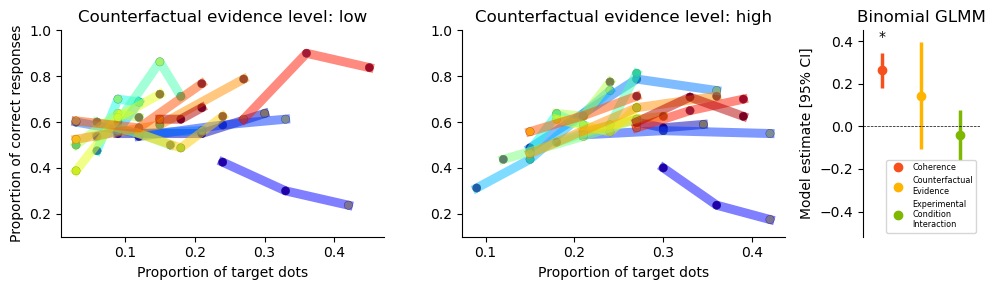

In [18]:
# accuracy plot
subjects = beh_select.subject.unique()
results = accuracy_export
sub_data = beh_select.groupby(["subject", "coherence_level", "counterfactual_label"]).response_correct.mean().reset_index()
stats_title = "Binomial GLMM"

cmap = colormaps.get_cmap("jet")

markers = ["o", "^", "p", "*"]
subj_colors = [cmap(i)[:3] for i in np.linspace(0.05, 0.95, num=subjects.shape[0])]
term_colors = ["#f6511d","#ffb400","#7fb800","#0d2c54"]

f, ax = plt.subplots(1, 3, figsize=(10, 3), width_ratios=(0.55, 0.55, 0.2))

for cf_ix, cf in enumerate(sub_data.counterfactual_label.unique()):
    for sub_ix, subject in enumerate(subjects):
        d = sub_data.loc[
            (sub_data.subject == subject) &
            (sub_data.counterfactual_label == cf)
        ]
        ax[cf_ix].plot(d.coherence_level, d.response_correct, c=subj_colors[sub_ix], lw=6.5, alpha=0.5)
        ax[cf_ix].scatter(d.coherence_level, d.response_correct, c=subj_colors[sub_ix], marker="o", lw=0.2, edgecolors="black")
    ax[cf_ix].set_title(f"Counterfactual evidence level: {cf}")
    ax[cf_ix].set_xlabel(f"Proportion of target dots")

    # ax[cf_ix].set_xticks(np.linspace(0.0, 0.6, num=7))
    ax[cf_ix].set_ylim(0.1, 1)
    [ax[cf_ix].spines[loc].set_visible(False) for loc in ["top", "right"]];
    

ax[0].set_ylabel("Proportion of correct responses")

x_spot = np.linspace(0, 1, results.shape[0])
margin = np.diff(x_spot)[0]/2

pos_sig = results.conf_high.to_numpy().max() * 1.06
vals = results[["conf_low", "conf_high"]].values.flatten()
min_lat = vals.min()
max_lat = vals.max()
margin_bottom = (abs(max_lat) + abs(vals.min())) * 0.65
margin_top = (abs(max_lat) + abs(vals.min())) * 0.1

for index, row in results.iterrows():
    estimate = row.estimate
    err_low = abs(estimate - row.conf_low)
    err_high = abs(row.conf_high - estimate)

    ax[2].errorbar(
        [x_spot[index]], [estimate], 
        yerr=[[err_low], [err_high]],
        fmt="o", lw=2.5, label=terms_nice[row.term],
        color=term_colors[index]
    )
    if row.p_value < 0.05:
        sig = "*"
    else:
        sig = " "

    ax[2].text(
        x_spot[index], pos_sig, sig,
        horizontalalignment="center",
        verticalalignment="center",
    )

ax[2].set_xlim(0-margin, 1+margin)
ax[2].set_ylim(min_lat - margin_bottom, max_lat + margin_top)
ax[2].legend(fontsize="xx-small", loc=4)
ax[2].set_title(stats_title)
ax[2].set_ylabel("Model estimate [95% CI]")
ax[2].axhline(0, color="black", linestyle="dashed", lw=0.5)
ax[2].set_xticks([], minor=False)
[ax[2].spines[loc].set_visible(False) for loc in ["top", "right", "bottom"]];
plt.tight_layout()

f.savefig("/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/GLMM_accuracy.svg")

In [ ]:
# confidence GLMM

confidence = glmer(
    # formula="scale_response ~ coherence_level + counterfactual_label + response_correct + (coherence_level:counterfactual_label) + (1 | subject)",
    formula="scale_response ~ coherence_label + counterfactual_label + response_correct + (coherence_label:counterfactual_label) + (1 | subject)",
    data=data,
    family="gaussian"
)
confidence.fit()

confidence_export = confidence.result_fit.to_pandas()
confidence_export = confidence_export.loc[confidence_export.term != "(Intercept)"].reset_index()

confidence.result_fit.to_pandas()

In [ ]:
# confidence plot
results = confidence_export
sub_data = beh_select.groupby(["subject", "coherence_label", "counterfactual_label", "response_correct"]).scale_response.mean().reset_index()
stats_title = "Gaussian GLMM"

sub_data.scale_response = sub_data.scale_response * 100

subjects = beh_select.subject.unique()
cmap = colormaps.get_cmap("jet")
subj_colors = [cmap(i)[:3] for i in np.linspace(0.05, 0.95, num=subjects.shape[0])]


corr_markers = ["o", "X"]
corr_linestyle = [(0, ()), (0, (1, 1))]
# subj_colors = ["#9b5de5", "#f15bb5", "#fee440", "#00bbf9", "#00f5d4"]
term_colors = ["#f6511d","#ffb400","#7fb800","#0d2c54", "#9b5de5"]

f, ax = plt.subplots(1, 3, figsize=(10, 3), width_ratios=(0.55, 0.55, 0.2))

for cf_ix, cf in enumerate(sub_data.counterfactual_label.unique()):
    for sub_ix, subject in enumerate(subjects):
        for corr_ix, resp in enumerate([True, False]):
            d = sub_data.loc[
                (sub_data.counterfactual_label == cf) &
                (sub_data.subject == subject) &
                (sub_data.response_correct == resp)
            ]
            relative = d.scale_response.loc[d.coherence_label == 1].values[0]
            ax[cf_ix].plot(d.coherence_label, d.scale_response - relative, c=subj_colors[sub_ix], lw=6.5, alpha=0.5, linestyle=corr_linestyle[corr_ix])
            # ax[cf_ix].plot(d.coherence_label, d.scale_response, c=subj_colors[sub_ix], lw=6.5, alpha=0.5, linestyle=corr_linestyle[corr_ix])
            # ax[cf_ix].scatter(d.coherence_level, d.scale_response, c=subj_colors[sub_ix], marker=corr_markers[corr_ix], lw=0.2, edgecolors="black")
    ax[cf_ix].set_title(f"Counterfactual evidence level: {cf}")
    ax[cf_ix].set_xlabel(f"Proportion of target dots")

    # ax[cf_ix].set_xticks(np.linspace(0.0, 0.5, num=6))
    # ax[cf_ix].set_ylim(5, 85)
    
    [ax[cf_ix].spines[loc].set_visible(False) for loc in ["top", "right"]];
    ax[0].set_ylabel("Relative Mean Confidence [%]")

    x_spot = np.linspace(0, 1, results.shape[0])
    margin = np.diff(x_spot)[0]/2

    pos_sig = results.conf_high.to_numpy().max() * 1.06
    vals = results[["conf_low", "conf_high"]].values.flatten()
    min_lat = vals.min()
    max_lat = vals.max()
    margin_bottom = (abs(max_lat) + abs(vals.min())) * 0.65
    margin_top = (abs(max_lat) + abs(vals.min())) * 0.1
    
for index, row in results.iterrows():
    estimate = row.estimate
    err_low = abs(estimate - row.conf_low)
    err_high = abs(row.conf_high - estimate)

    ax[2].errorbar(
        [x_spot[index]], [estimate], 
        yerr=[[err_low], [err_high]],
        fmt="o", lw=2.5, label=terms_nice[row.term],
        color=term_colors[index]
    )
    if row.p_value < 0.05:
        sig = "*"
    else:
        sig = " "

    ax[2].text(
        x_spot[index], pos_sig, sig,
        horizontalalignment="center",
        verticalalignment="center",
    )

ax[2].set_xlim(0-margin, 1+margin)
ax[2].set_ylim(min_lat - margin_bottom, max_lat + margin_top)
ax[2].legend(fontsize="xx-small", loc=4)
ax[2].set_title(stats_title)
ax[2].set_ylabel("Model estimate [95% CI]")
ax[2].axhline(0, color="black", linestyle="dashed", lw=0.5)
ax[2].set_xticks([], minor=False)
[ax[2].spines[loc].set_visible(False) for loc in ["top", "right", "bottom"]];
plt.tight_layout()

f.savefig("/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/GLMM_confidence.svg")

In [ ]:
# RT GLMM

rt = glmer(
    formula="rt ~ coherence_level + counterfactual_label + response_correct + (coherence_level:counterfactual_label) + (1 | subject)",
    data=data,
    family="gaussian"
)
rt.fit()

rt_export = rt.result_fit.to_pandas()
rt_export = rt_export.loc[rt_export.term != "(Intercept)"].reset_index()


rt.result_fit.to_pandas()

In [ ]:
# confidence plot
results = rt_export
sub_data = beh_select.groupby(["subject", "coherence_level", "counterfactual_label", "response_correct"]).rt.mean().reset_index()
stats_title = "Gaussian GLMM"

# sub_data.scale_response = sub_data.scale_response * 100

subjects = beh_select.subject.unique()
cmap = colormaps.get_cmap("jet")
subj_colors = [cmap(i)[:3] for i in np.linspace(0.05, 0.95, num=subjects.shape[0])]


corr_markers = ["o", "X"]
corr_linestyle = [(0, ()), (0, (1, 1))]
# subj_colors = ["#9b5de5", "#f15bb5", "#fee440", "#00bbf9", "#00f5d4"]
term_colors = ["#f6511d","#ffb400","#7fb800","#0d2c54"]

f, ax = plt.subplots(1, 3, figsize=(10, 3), width_ratios=(0.55, 0.55, 0.2))

for cf_ix, cf in enumerate(sub_data.counterfactual_label.unique()):
    for sub_ix, subject in enumerate(subjects):
        for corr_ix, resp in enumerate([True, False]):
            d = sub_data.loc[
                (sub_data.counterfactual_label == cf) &
                (sub_data.subject == subject) &
                (sub_data.response_correct == resp)
            ]

            ax[cf_ix].plot(d.coherence_level, d.rt, c=subj_colors[sub_ix], lw=6.5, alpha=0.5, linestyle=corr_linestyle[corr_ix])
            # ax[cf_ix].scatter(d.coherence_level, d.rt, c=subj_colors[sub_ix], marker=corr_markers[corr_ix], lw=0.2, edgecolors="black")
    ax[cf_ix].set_title(f"Counterfactual evidence level: {cf}")
    ax[cf_ix].set_xlabel(f"Proportion of target dots")

    # ax[cf_ix].set_xticks(np.linspace(0.0, 0.6, num=7))
    # ax[cf_ix].set_ylim(10, 70)
    [ax[cf_ix].spines[loc].set_visible(False) for loc in ["top", "right"]];
    ax[0].set_ylabel("Mean Log Reaction Time [s]")

    x_spot = np.linspace(0, 1, results.shape[0])
    margin = np.diff(x_spot)[0]/2

    pos_sig = results.conf_high.to_numpy().max() * 1.06
    vals = results[["conf_low", "conf_high"]].values.flatten()
    min_lat = vals.min()
    max_lat = vals.max()
    margin_bottom = (abs(max_lat) + abs(vals.min())) * 0.65
    margin_top = (abs(max_lat) + abs(vals.min())) * 0.1
    
for index, row in results.iterrows():
    estimate = row.estimate
    err_low = abs(estimate - row.conf_low)
    err_high = abs(row.conf_high - estimate)

    ax[2].errorbar(
        [x_spot[index]], [estimate], 
        yerr=[[err_low], [err_high]],
        fmt="o", lw=2.5, label=terms_nice[row.term],
        color=term_colors[index]
    )
    if row.p_value < 0.05:
        sig = "*"
    else:
        sig = " "

    ax[2].text(
        x_spot[index], pos_sig, sig,
        horizontalalignment="center",
        verticalalignment="center",
    )

ax[2].set_xlim(0-margin, 1+margin)
ax[2].set_ylim(min_lat - margin_bottom, max_lat + margin_top)
ax[2].legend(fontsize="xx-small", loc=4)
ax[2].set_title(stats_title)
ax[2].set_ylabel("Model estimate [95% CI]")
ax[2].axhline(0, color="black", linestyle="dashed", lw=0.5)
ax[2].set_xticks([], minor=False)
[ax[2].spines[loc].set_visible(False) for loc in ["top", "right", "bottom"]];
plt.tight_layout()

f.savefig("/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/GLMM_RT.svg")

In [ ]:
beh_all.head()